# **LABORATORIO DE PROCESAMIENTO DIGITAL DE IMAGENES (PDI)**

Pablo Andres Villareal Cardenas - 2043233

Alan Zahir Lopez Rodriguez - 2103115


# **PRÁCTICA 8. *APLICACIÓN DE FILTROS***

---

**Importación de librerías y carga de las imágenes**

In [ ]:
import cv2
import numpy as np
import matplotlib.pyplot as plt

# Cargar las imagenes en escala de grises
img_rx = cv2.imread('/content/radiografia.jpg', cv2.IMREAD_GRAYSCALE)
img_frec_1 = cv2.imread('/content/endoscopia.jpg', cv2.IMREAD_GRAYSCALE)

> Se importan las librerías necesarias para la práctica: `cv2` (OpenCV) para la aplicación de los filtros, `numpy` para la construcción y manipulación de las máscaras y espectros de frecuencia, y `matplotlib.pyplot` para la visualización de resultados.

> Para la Parte I se utiliza una sola radiografía en escala de grises, sobre la cual se aplican los filtros espaciales. Para la Parte II se utiliza esta misma imagen, y además se carga la imagen (`img_frec_1`), ya que las instrucciones piden aplicar los filtros en el dominio de la frecuencia sobre dos imágenes diferentes y comparar sus resultados.

# **Parte I. Filtros con máscaras espaciales personalizadas**

**Filtros de suavizado (media, gaussiano, mediana)**

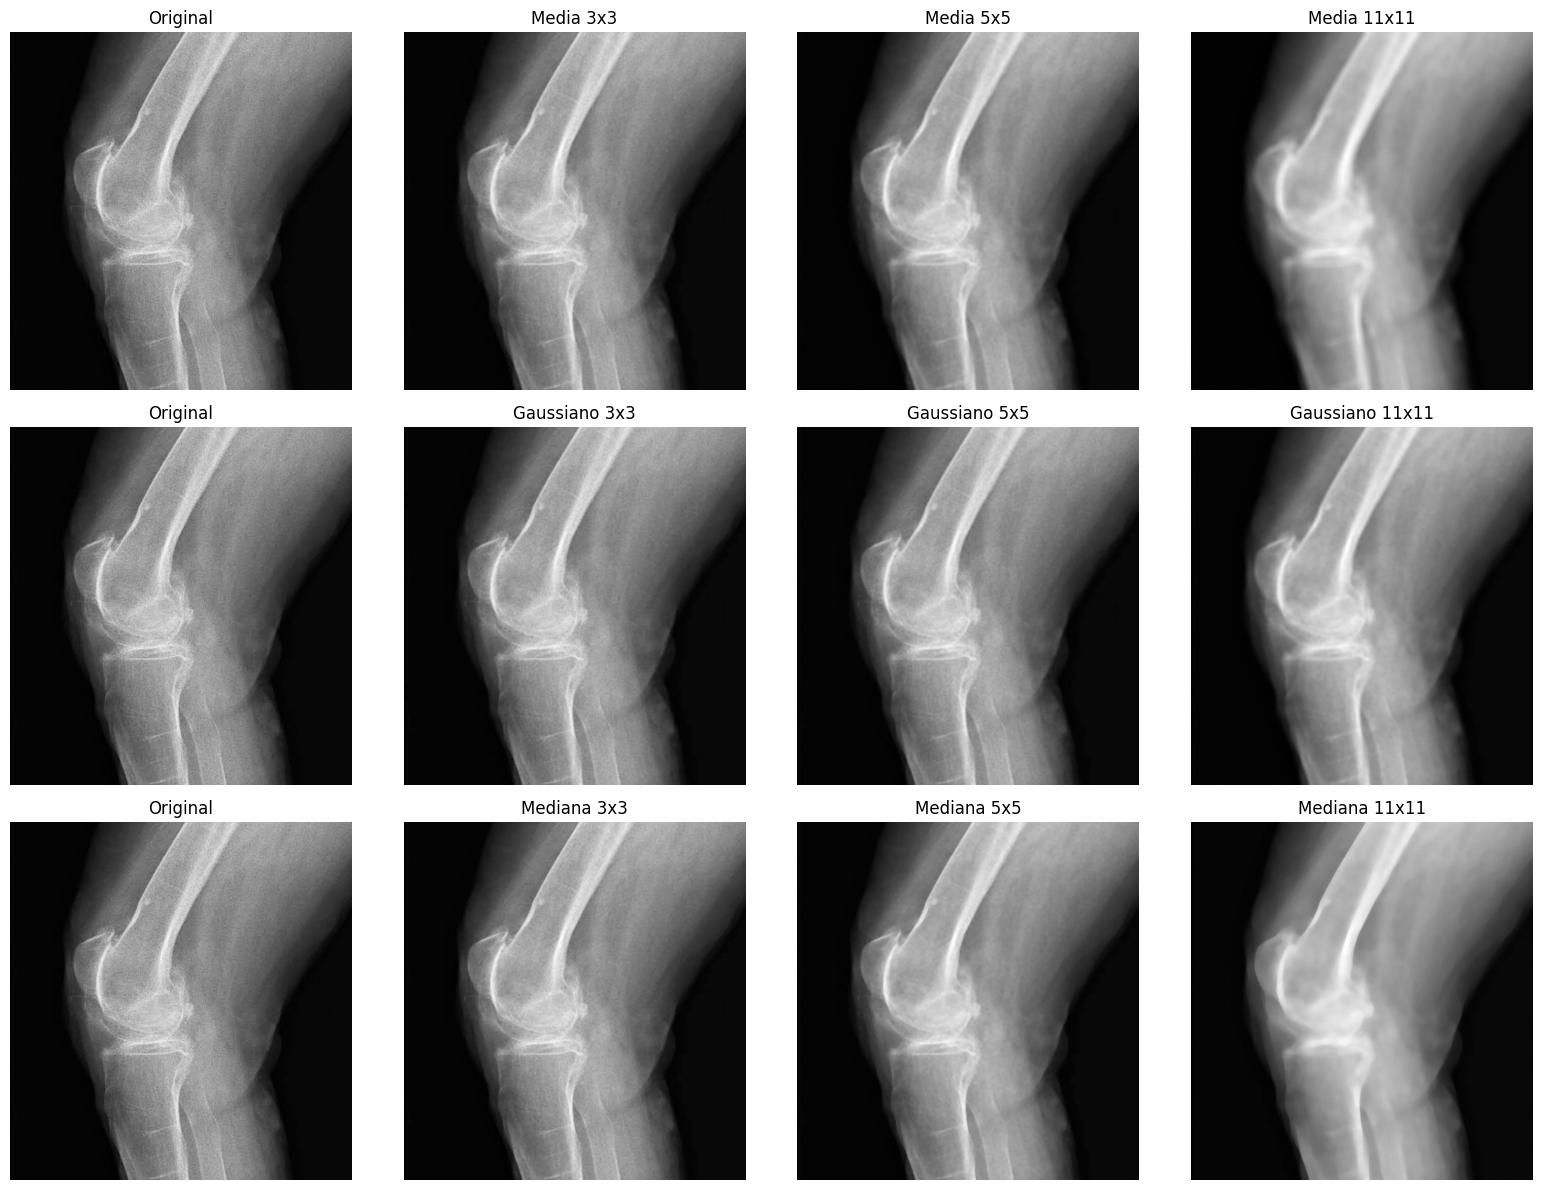

In [ ]:
# Tamaños de kernel a comparar
kernels = [3, 5, 11]

# Filtro de media (promedio simple de los vecinos) para cada tamaño de kernel
img_media = [cv2.blur(img_rx, (k, k)) for k in kernels]

# Filtro gaussiano (promedio ponderado según una distribución normal) para cada tamaño de kernel
img_gauss = [cv2.GaussianBlur(img_rx, (k, k), 0) for k in kernels]

# Filtro de mediana (sustituye cada píxel por la mediana de su vecindad) para cad atamaño de kernel
img_mediana = [cv2.medianBlur(img_rx, k) for k in kernels]

# Mostrar los resultados y la imagen original como referencia
fig, axes = plt.subplots(3, 4, figsize=(16, 12))

for fila, (nombre, resultados) in enumerate(zip(
        ['Media', 'Gaussiano', 'Mediana'],
        [img_media, img_gauss, img_mediana])):

    axes[fila, 0].imshow(img_rx, cmap='gray')
    axes[fila, 0].set_title('Original')
    axes[fila, 0].axis('off')

    for col, k in enumerate(kernels):
        axes[fila, col + 1].imshow(resultados[col], cmap='gray')
        axes[fila, col + 1].set_title(f'{nombre} {k}x{k}')
        axes[fila, col + 1].axis('off')

plt.tight_layout()
plt.show()

> Se compararon tres filtros de suavizado (media, gaussiano y mediana) usando tres tamaños de kernel (3x3, 5x5 y 11x11) sobre la misma radiografía. El filtro de media (`cv2.blur`) promedia de manera uniforme los valores de los píxeles vecinos, el filtro gaussiano (`cv2.GaussianBlur`) pondera esos vecinos según una distribución normal centrada en el píxel actual (dando más peso al centro), y el filtro de mediana (`cv2.medianBlur`) sustituye cada píxel por la mediana de su vecindad, lo cual lo hace especialmente efectivo contra ruido tipo "sal y pimienta" sin difuminar tanto los bordes como los otros dos.

> Conforme aumenta el tamaño del kernel (de 3x3 a 11x11), el suavizado se vuelve más agresivo y hace que las imagenes vayan perdiendo más sus detalles fino s. Un kernel 3x3 resulta adecuado cuando se busca atenuar ruido leve conservando la mayoría de las estructuras anatómicas, mientras que un kernel 11x11 sólo se justifica cuando el ruido es muy severo o cuando el resultado se usará únicamente como referencia de baja frecuencia (antes de un realce de bordes p. ej), ya que a ese tamaño se difuminan estructuras pequeñas que podrían ser relevantes para el diagnóstico.

**Filtros de detección de bordes (Sobel, Laplaciano)**

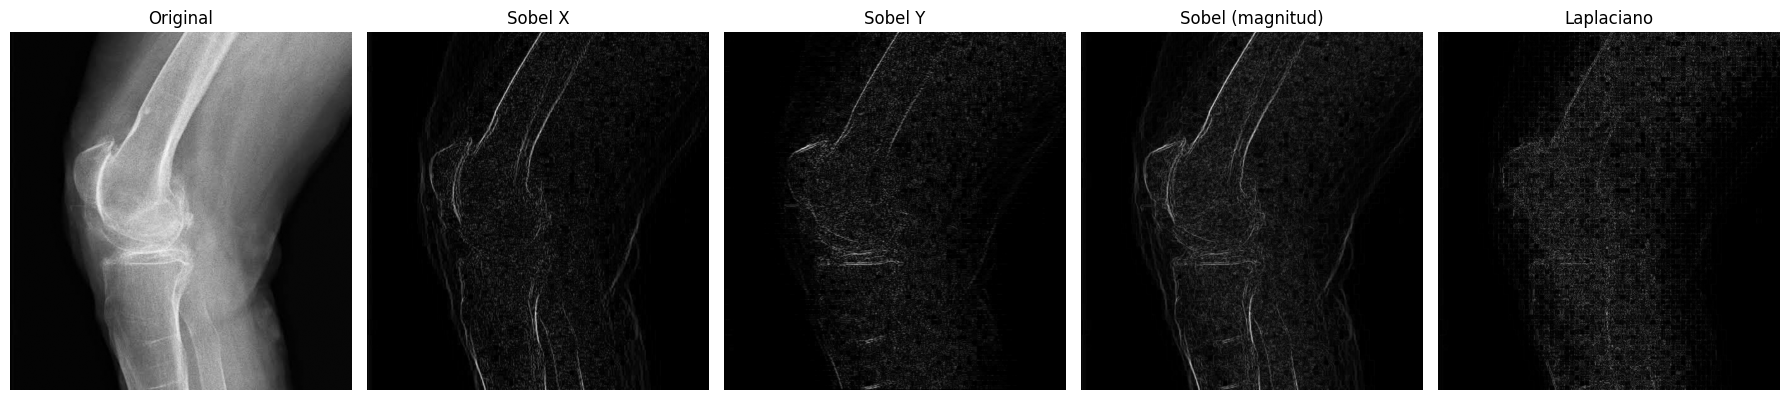

In [ ]:
# Filtro Sobel (x,y, con kernel de 3x3)
sobel_x = cv2.Sobel(img_rx, cv2.CV_64F, 1, 0, ksize=3)
sobel_y = cv2.Sobel(img_rx, cv2.CV_64F, 0, 1, ksize=3)
sobel_mag = cv2.magnitude(sobel_x, sobel_y)

# Filtro Laplaciano (kernel de 3x3)
laplaciano = cv2.Laplacian(img_rx, cv2.CV_64F, ksize=3)

# Normalizar los resultados a 8 bits (con uint8) para poder visualizarlos correctamente
def normalizar(img):
    return cv2.normalize(img, None, 0, 255, cv2.NORM_MINMAX).astype(np.uint8)

sobel_x_vis = normalizar(np.abs(sobel_x))
sobel_y_vis = normalizar(np.abs(sobel_y))
sobel_mag_vis = normalizar(sobel_mag)
laplaciano_vis = normalizar(np.abs(laplaciano))

# Mostrar resultados de Sobel ([x,y] y magnitud), Laplaciano e imagen original
plt.figure(figsize=(18, 4))

plt.subplot(1, 5, 1)
plt.imshow(img_rx, cmap='gray')
plt.title('Original')
plt.axis('off')

plt.subplot(1, 5, 2)
plt.imshow(sobel_x_vis, cmap='gray')
plt.title('Sobel X')
plt.axis('off')

plt.subplot(1, 5, 3)
plt.imshow(sobel_y_vis, cmap='gray')
plt.title('Sobel Y')
plt.axis('off')

plt.subplot(1, 5, 4)
plt.imshow(sobel_mag_vis, cmap='gray')
plt.title('Sobel (magnitud)')
plt.axis('off')

plt.subplot(1, 5, 5)
plt.imshow(laplaciano_vis, cmap='gray')
plt.title('Laplaciano')
plt.axis('off')

plt.tight_layout()
plt.show()

> Los filtros de Sobel (`cv2.Sobel`) se calculan por separado para la dirección x y la dirección y, por lo que cada uno resalta principalmente los bordes perpendiculares a su dirección (Sobel X resalta bordes verticales, Sobel Y horizontales); al obtener la magnitud mediante `cv2.magnitude`, se obtiene la magnitud total del gradiente, resaltando bordes en cualquier orientación. El Laplaciano (`cv2.Laplacian`), al ser un operador de segunda derivada, no distingue direcciones y resalta por igual todos los bordes, pero es más sensible al ruido que Sobel.

> En ambos casos, los resultados se normalizaron con `cv2.normalize` (y `np.abs` para el caso del Laplaciano, que produce valores negativos) para poder visualizarlos en el rango de 8 bits [0, 255].

**Modificación manual de máscaras y filtro de Kirsch**

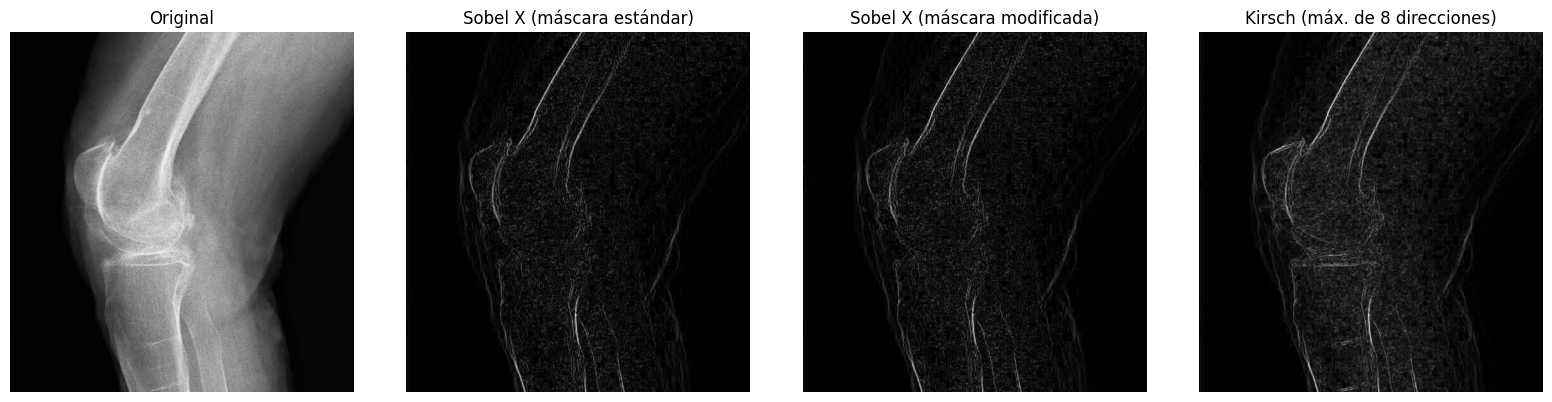

In [ ]:
# Máscara de Sobel X definida manualmente (equivalente a la que usa cv2.Sobel internamente)
sobel_x_estandar_kernel = np.array([[-1, 0, 1], [-2, 0, 2], [-1, 0, 1]], dtype=np.float32)

# Variante modificada (acentuando mas los bordes horizontales por incremento del peso de la fila central)
sobel_x_modificado_kernel = np.array([[-1, 0, 1], [-4, 0, 4], [-1, 0, 1]], dtype=np.float32)

sobel_x_estandar = cv2.filter2D(img_rx, cv2.CV_64F, sobel_x_estandar_kernel)
sobel_x_modificado = cv2.filter2D(img_rx, cv2.CV_64F, sobel_x_modificado_kernel)

sobel_x_estandar_vis = normalizar(np.abs(sobel_x_estandar))
sobel_x_modificado_vis = normalizar(np.abs(sobel_x_modificado))

# Máscaras de Kirsch rotada c/u 45° con respecto a la anterior
kirsch_kernels = [
    np.array([[ 5,  5,  5], [-3,  0, -3], [-3, -3, -3]]),  # NORTE
    np.array([[-3,  5,  5], [-3,  0,  5], [-3, -3, -3]]),  # NORTEST
    np.array([[-3, -3,  5], [-3,  0,  5], [-3, -3,  5]]),  # EST
    np.array([[-3, -3, -3], [-3,  0,  5], [-3,  5,  5]]),  # SURESTE
    np.array([[-3, -3, -3], [-3,  0, -3], [ 5,  5,  5]]),  # SUR
    np.array([[-3, -3, -3], [ 5,  0, -3], [ 5,  5, -3]]),  # SUROESTE
    np.array([[ 5, -3, -3], [ 5,  0, -3], [ 5, -3, -3]]),  # OESTE
    np.array([[ 5,  5, -3], [ 5,  0, -3], [-3, -3, -3]]),  # NOROESTE
]

# Aplicar las 8 máscaras y conservar respesta de mayor magnitud en cada píxel
respuestas_kirsch = [cv2.filter2D(img_rx, cv2.CV_64F, k.astype(np.float32)) for k in kirsch_kernels]
kirsch = np.max(respuestas_kirsch, axis=0)
kirsch_vis = normalizar(kirsch)

# Mostrar resultados (Sobel estándar vs la modificada manualmente, y Kirsch)
plt.figure(figsize=(16, 4))

plt.subplot(1, 4, 1)
plt.imshow(img_rx, cmap='gray')
plt.title('Original')
plt.axis('off')

plt.subplot(1, 4, 2)
plt.imshow(sobel_x_estandar_vis, cmap='gray')
plt.title('Sobel X (máscara estándar)')
plt.axis('off')

plt.subplot(1, 4, 3)
plt.imshow(sobel_x_modificado_vis, cmap='gray')
plt.title('Sobel X (máscara modificada)')
plt.axis('off')

plt.subplot(1, 4, 4)
plt.imshow(kirsch_vis, cmap='gray')
plt.title('Kirsch (máx. de 8 direcciones)')
plt.axis('off')

plt.tight_layout()
plt.show()

> Para observar el efecto de modificar una máscara manualmente, se construyó primero la máscara de Sobel X estándar con `cv2.filter2D` (obteniendo el mismo resultado que `cv2.Sobel`), y después se generó una variante en la que se aumentó el peso de la fila central de -2/2 a -4/4. Esto acentúa aún más la respuesta sobre bordes horizontales, haciendo la imagen de bordes resultante más contrastada, pero también más sensible al ruido.

> El operador de Kirsch utiliza 8 máscaras direccionales (una por cada orientación a 45°) en lugar de solo 2 como Sobel. Al aplicar las 8 máscaras con `cv2.filter2D` y conservar en cada píxel la respuesta de mayor magnitud (`np.max`), se obtiene un detector de bordes omnidireccional que, a diferencia de la magnitud de Sobel, no promedia las respuestas de las distintas orientaciones sino que selecciona siempre la dirección en la que el borde es más fuerte.

**Máscara de realce personalizada**

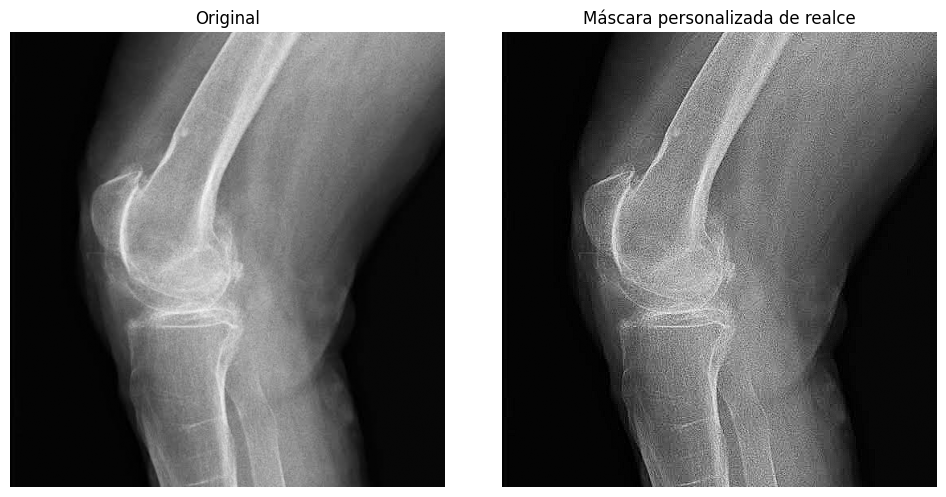

In [ ]:
# Máscara personalizada de realce
mascara_realce = np.array([[ 0, -1,  0], [-1,  5, -1], [ 0, -1,  0]], dtype=np.float32)

img_realce = cv2.filter2D(img_rx, cv2.CV_64F, mascara_realce)
img_realce_vis = np.clip(img_realce, 0, 255).astype(np.uint8)

# Mostrar resultado junto con la imagen original
plt.figure(figsize=(10, 5))

plt.subplot(1, 2, 1)
plt.imshow(img_rx, cmap='gray')
plt.title('Original')
plt.axis('off')

plt.subplot(1, 2, 2)
plt.imshow(img_realce_vis, cmap='gray')
plt.title('Máscara personalizada de realce')
plt.axis('off')

plt.tight_layout()
plt.show()

> La máscara personalizada se diseñó como un filtro de realce (sharpening) tipo unsharp mask: en este, el coeficiente central (5) conserva la intensidad propia del píxel, mientras que los cuatro vecinos ortogonales (-1) se restan, de forma que la suma total de los coeficientes de la máscara es 1 (se conserva el brillo promedio de la imagen) pero se amplifica la diferencia entre cada píxel y sus vecinos inmediatos. Al aplicarla con `cv2.filter2D` se obtiene una imagen en la que los bordes y estructuras finas se perciben más nítidos que en la radiografía original, sin alterar drásticamente las zonas de intensidad uniforme.

# **Parte II. Filtros en el dominio de la frecuencia con parametros modificables**

**Transformacion al dominio de la frecuencia (Fourier)**

In [ ]:
def calcular_fft(img):
    # Calcular FFT 2D de una imagen y regresa la transformada centrada junto con su espectro de magnitud
    f = np.fft.fft2(img)
    fshift = np.fft.fftshift(f)
    espectro = 20 * np.log(np.abs(fshift) + 1)
    return fshift, espectro

def mascara_circular(forma, radio, tipo='bajas'):
    # Crear máscara circular centrada en el espectro: pb conserva el centro, pa lo bloquea
    filas, columnas = forma
    cy, cx = filas // 2, columnas // 2
    y, x = np.ogrid[:filas, :columnas]
    distancia = np.sqrt((x - cx) ** 2 + (y - cy) ** 2)
    if tipo == 'bajas':
        return (distancia <= radio).astype(np.float32)
    return (distancia > radio).astype(np.float32)

def mascara_anillo(forma, radio_interno, radio_externo):
    # Máscara pasa altas en forma de anillo: conserva únicamente una banda de frecuencias medias
    filas, columnas = forma
    cy, cx = filas // 2, columnas // 2
    y, x = np.ogrid[:filas, :columnas]
    distancia = np.sqrt((x - cx) ** 2 + (y - cy) ** 2)
    return ((distancia >= radio_interno) & (distancia <= radio_externo)).astype(np.float32)

def mascara_cruz(forma, grosor):
    # Máscara pasa altas en forma de cruz: bloquea una franja horizontal y vertical de bajas frecuencias
    filas, columnas = forma
    cy, cx = filas // 2, columnas // 2
    mascara = np.ones((filas, columnas), dtype=np.float32)
    mascara[cy - grosor:cy + grosor, :] = 0
    mascara[:, cx - grosor:cx + grosor] = 0
    return mascara

def aplicar_mascara(fshift, mascara):
    # Aplica una máscara en el dominio de la frecuencia y regresa la imagen filtrada (trans inversa)
    f_filtrado = fshift * mascara
    img_filtrada = np.fft.ifft2(np.fft.ifftshift(f_filtrado))
    return np.abs(img_filtrada)

> `calcular_fft` obtiene la Transformada de Fourier 2D de la imagen (`np.fft.fft2`) y la centra (`np.fft.fftshift`) para que las frecuencias bajas queden en el centro del espectro y las altas en los bordes, que es la convención habitual para construir las máscaras. El espectro de magnitud se visualiza en escala logarítmica porque los valores de la FFT varían en varios órdenes de magnitud.

> `mascara_circular` genera una máscara binaria pasa bajas (círculo centrado que conserva solo las frecuencias dentro de un radio) o pasa altas (su complemento, que bloquea ese mismo círculo central). `mascara_anillo` combina ambas ideas para conservar únicamente una banda de frecuencias medias, y `mascara_cruz` bloquea una franja horizontal y vertical alrededor del centro, eliminando específicamente las frecuencias puramente horizontales y verticales. Finalmente, `aplicar_mascara` multiplica la transformada por la máscara correspondiente y regresa al dominio espacial con la transformada inversa (`np.fft.ifft2`), conservando solo la magnitud del resultado complejo.

**Pasa bajas con diferentes radios de corte**

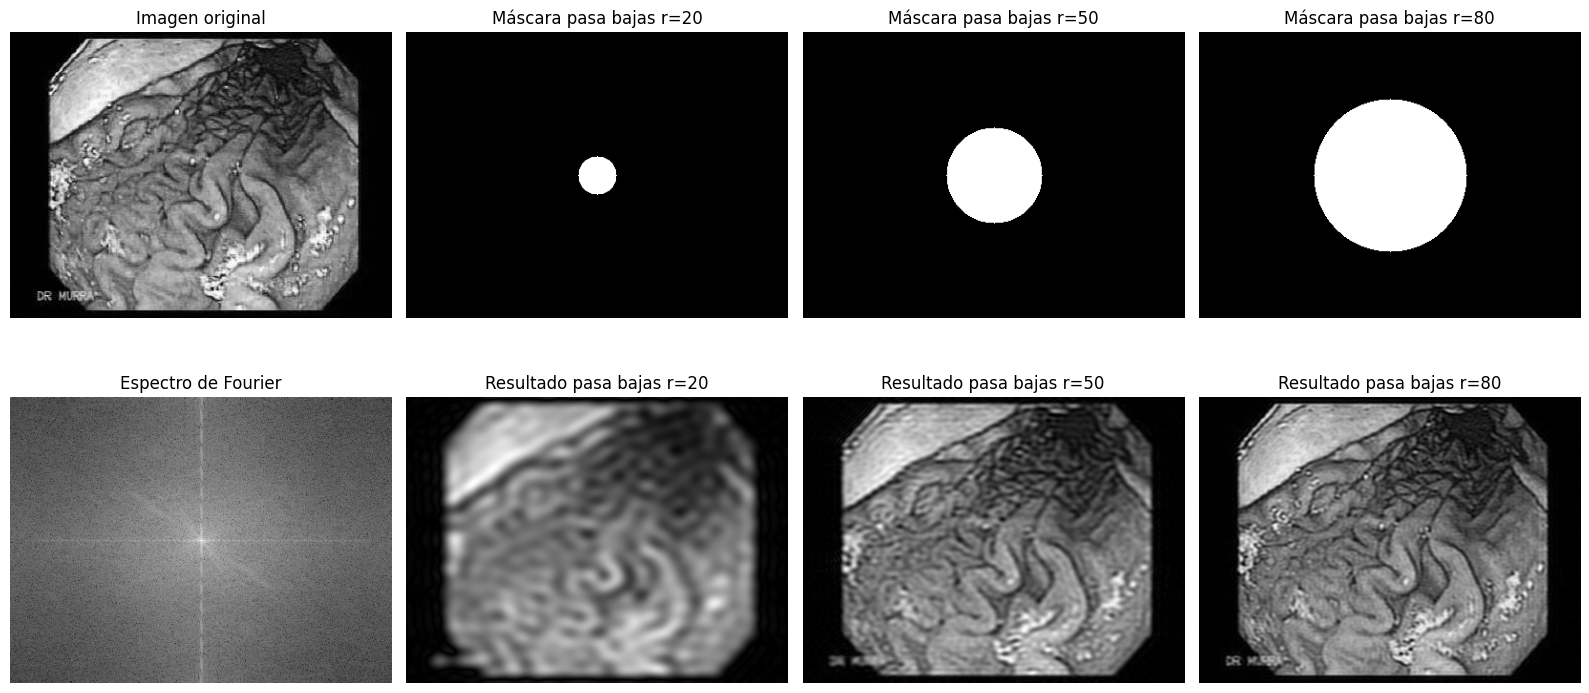

In [ ]:
fshift_1, espectro_1 = calcular_fft(img_frec_1)

# Filtros pasa bajas con tres radios de corte
radios_bajas = [20, 50, 80]
mascaras_bajas = [mascara_circular(img_frec_1.shape, r, 'bajas') for r in radios_bajas]
resultados_bajas = [aplicar_mascara(fshift_1, m) for m in mascaras_bajas]

# Mostrar resultados y la imagen original
fig, axes = plt.subplots(2, 4, figsize=(16, 8))

axes[0, 0].imshow(img_frec_1, cmap='gray')
axes[0, 0].set_title('Imagen original')
axes[0, 0].axis('off')

axes[1, 0].imshow(espectro_1, cmap='gray')
axes[1, 0].set_title('Espectro de Fourier')
axes[1, 0].axis('off')

for i, r in enumerate(radios_bajas):
    axes[0, i + 1].imshow(mascaras_bajas[i], cmap='gray')
    axes[0, i + 1].set_title(f'Máscara pasa bajas r={r}')
    axes[0, i + 1].axis('off')

    axes[1, i + 1].imshow(resultados_bajas[i], cmap='gray')
    axes[1, i + 1].set_title(f'Resultado pasa bajas r={r}')
    axes[1, i + 1].axis('off')

plt.tight_layout()
plt.show()

> Se aplicaron tres filtros pasa bajas circulares con radios de corte de 20, 50 y 80 píxeles sobre la primera imagen médica. Entre más pequeño es el radio, menos frecuencias (incluyendo las altas frecuencias asociadas a bordes y ruido) se conservan, por lo que la imagen resultante se ve considerablemente más borrosa y con mayor pérdida de detalle (r 20); conforme el radio aumenta (r 50, r 80), se conservan más componentes de frecuencia media y alta, y la imagen filtrada se asemeja cada vez más a la original, con menos suavizado.

**Pasa altas con diferentes configuraciones**

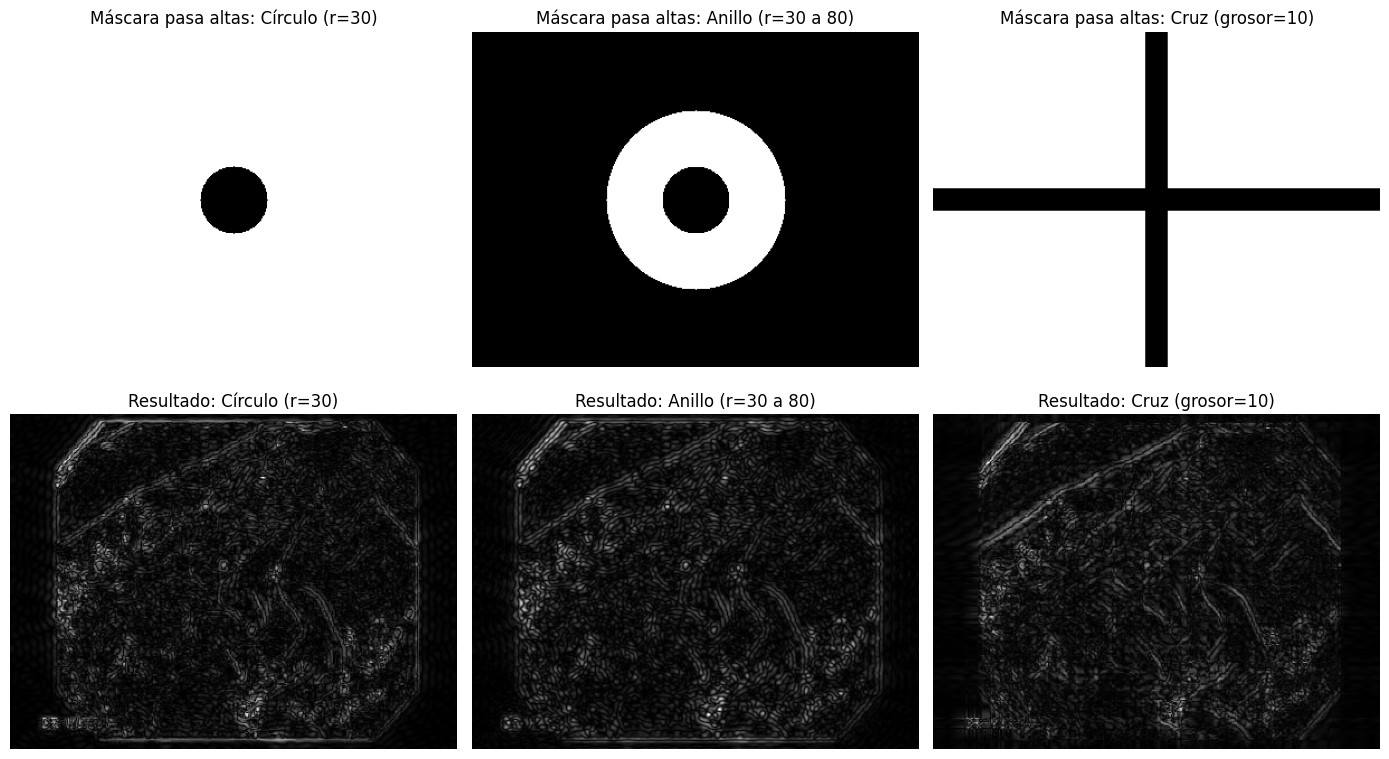

In [ ]:
# Filtro pasa altas circular (bloquea un círculo central de bajas frecuencias)
mascara_altas_circulo = mascara_circular(img_frec_1.shape, 30, 'altas')
resultado_altas_circulo = aplicar_mascara(fshift_1, mascara_altas_circulo)

# Filtro pasa altas en anillo (conserva solo una banda de frecuencias medias)
mascara_altas_anillo = mascara_anillo(img_frec_1.shape, 30, 80)
resultado_altas_anillo = aplicar_mascara(fshift_1, mascara_altas_anillo)

# Filtro pasa altas en cruz (elimina las frecuencias puramente horizontales y verticales)
mascara_altas_cruz = mascara_cruz(img_frec_1.shape, 10)
resultado_altas_cruz = aplicar_mascara(fshift_1, mascara_altas_cruz)

configuraciones = [
    ('Círculo (r=30)', mascara_altas_circulo, resultado_altas_circulo),
    ('Anillo (r=30 a 80)', mascara_altas_anillo, resultado_altas_anillo),
    ('Cruz (grosor=10)', mascara_altas_cruz, resultado_altas_cruz),
]

# Mostrar cada máscara pasa altas junto con el resultado de aplicarla
fig, axes = plt.subplots(2, 3, figsize=(14, 8))

for i, (nombre, mascara, resultado) in enumerate(configuraciones):
    axes[0, i].imshow(mascara, cmap='gray')
    axes[0, i].set_title(f'Máscara pasa altas: {nombre}')
    axes[0, i].axis('off')

    axes[1, i].imshow(resultado, cmap='gray')
    axes[1, i].set_title(f'Resultado: {nombre}')
    axes[1, i].axis('off')

plt.tight_layout()
plt.show()

> La configuración circular bloquea por completo un círculo central de bajas frecuencias y deja pasar el resto; el resultado resalta fuertemente los bordes y contornos, pero pierde casi toda la información de intensidad y las zonas de tono uniforme, ya que esas corresponden principalmente a frecuencias bajas. La configuración en anillo es menos agresiva, pues conserva una banda de frecuencias medias además de las altas, por lo que el resultado retiene algo más de la estructura general de la imagen junto con los bordes. La configuración en cruz, en cambio, no bloquea un área circular sino una franja horizontal y vertical, por lo que elimina específicamente patrones alineados con los ejes (por ejemplo, líneas horizontales o verticales periódicas) mientras conserva un ppoco mejor la información de intensidad general en comparación con el filtro circular.

**Prueba con una segunda imagen médica**

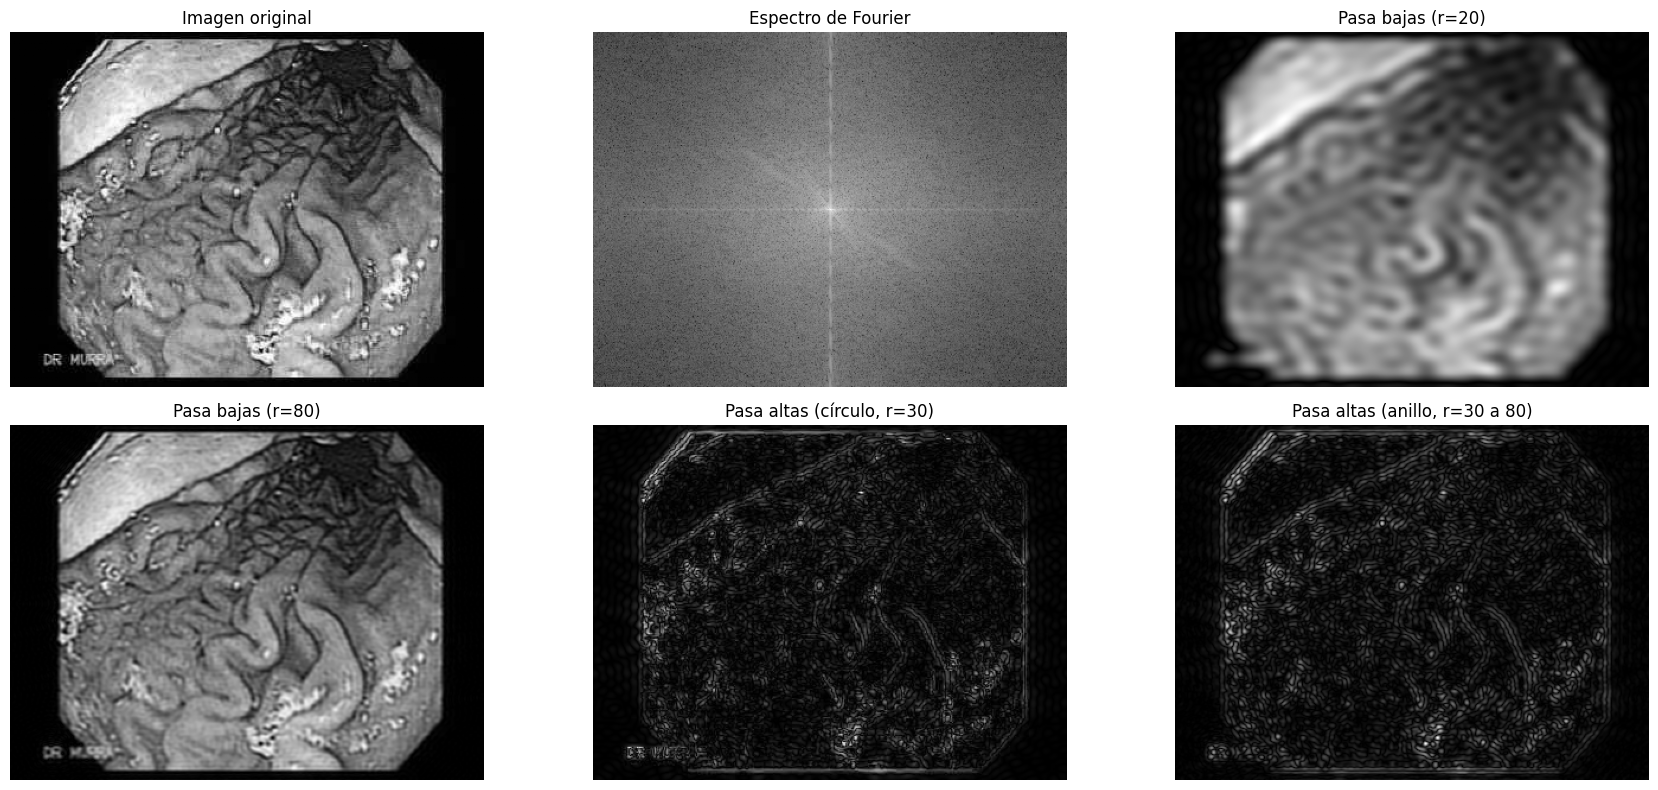

In [13]:
fshift_2, espectro_2 = calcular_fft(img_frec_1)

# Se repiten los mismos filtros pasa bajas y pasa altas sobre esta segunda imagen
mascara_bajas_2a = mascara_circular(img_frec_1.shape, 20, 'bajas')
mascara_bajas_2b = mascara_circular(img_frec_1.shape, 80, 'bajas')
resultado_bajas_2a = aplicar_mascara(fshift_2, mascara_bajas_2a)
resultado_bajas_2b = aplicar_mascara(fshift_2, mascara_bajas_2b)

mascara_altas_2a = mascara_circular(img_frec_1.shape, 30, 'altas')
mascara_altas_2b = mascara_anillo(img_frec_1.shape, 30, 80)
resultado_altas_2a = aplicar_mascara(fshift_2, mascara_altas_2a)
resultado_altas_2b = aplicar_mascara(fshift_2, mascara_altas_2b)

# Mostrar resultados e imagen original
plt.figure(figsize=(18, 8))

plt.subplot(2, 3, 1)
plt.imshow(img_frec_1, cmap='gray')
plt.title('Imagen original')
plt.axis('off')

plt.subplot(2, 3, 2)
plt.imshow(espectro_2, cmap='gray')
plt.title('Espectro de Fourier')
plt.axis('off')

plt.subplot(2, 3, 3)
plt.imshow(resultado_bajas_2a, cmap='gray')
plt.title('Pasa bajas (r=20)')
plt.axis('off')

plt.subplot(2, 3, 4)
plt.imshow(resultado_bajas_2b, cmap='gray')
plt.title('Pasa bajas (r=80)')
plt.axis('off')

plt.subplot(2, 3, 5)
plt.imshow(resultado_altas_2a, cmap='gray')
plt.title('Pasa altas (círculo, r=30)')
plt.axis('off')

plt.subplot(2, 3, 6)
plt.imshow(resultado_altas_2b, cmap='gray')
plt.title('Pasa altas (anillo, r=30 a 80)')
plt.axis('off')

plt.tight_layout()
plt.show()

> Al repetir los mismos filtros sobre la segunda imagen médica se observa el mismo comportamiento general (los filtros pasa bajas suavizan más entre menor es el radio, y los pasa altas resaltan bordes a costa de la información de intensidad), pero la magnitud del efecto depende del contenido de frecuencia particular de cada imagen: una imagen con más detalle fino y texturas (como un corte histológico) concentra más energía en las frecuencias altas, por lo que un filtro pasa bajas agresivo elimina una mayor proporción de su información útil en comparación con una imagen de estructuras más homogéneas, en donde la mayor parte de la energía del espectro se concentra cerca del centro (bajas frecuencias).